# Household Air Pollution & Childhood ARI — Statistical Analysis
**ARCeH Externship · Notebook 2 · Input: `Child_Environmental_Health_Cleaned.csv` (from Notebook 1)**

---

## Notebook 2: Purpose
Run the pre-chosen method, **survey-weighted logistic regression**, on the analysis-ready data, then read and interpret its output.

**Research question:** Is polluting cooking fuel (`solid_fuel`) associated with ARI symptoms (`ari`) among children under 5 in Cambodia, Indonesia, Myanmar, the Philippines and Timor-Leste, after accounting for kitchen location, wealth, maternal education, urban/rural residence, smoking in the home, breastfeeding, household size and country?

**Defended method choice:** I'm choosing logistic regression for this analysis. My outcome variable is `ari`, which is binary. My predictors are `solid_fuel` (binary), `kitchen_location` (nominal), `wealth_quintile` (ordinal), `mother_education` (ordinal), `smoking_in_home` (ordinal), `urban` (binary), `ever_breastfed` (binary), `household_size` (continuous) and `country` (nominal). Logistic regression is the right fit because it models a binary outcome while adjusting for several predictors of mixed types at once. Chi-square doesn't fit because it tests only two variables, and the unadjusted pooled comparison is distorted by country differences (Simpson's paradox).

| Part | Contents |
|---|---|
| 1. Setup & Load | Libraries, cleaned file, completeness checks |
| 2. Model Specification | Outcome, predictors, weights, clusters, events per predictor, overlap check |
| 3. Main Analysis | Crude → country-adjusted → fully adjusted models; saved output |
| 4. Secondary & Sensitivity Analyses | Exposure gradient, kerosene, fuel × country, each country, unweighted, Mantel-Haenszel |
| 5. Unpacking the Wealth Question | Fuel within each wealth level, fuel × wealth, wealth-free adjustment, age proxy |
| 6. Alternative Approaches | Propensity score weighting (overlap, balance, weighted risks); Cochran–Armitage trend test |
| 7. Model Fit | Discrimination (AUC) and calibration |
| 8. Visualizations | Forest plots, adjustment path, fuel by wealth level |
| 9. Interpretation | Four key numbers + three-sentence interpretation + what the follow-ups add |
| 10. Limitations & Final Conclusion | What the result cannot show; final stress-tested interpretation; further work |

---
# Part 1 · Setup & Load
Load the analysis-ready file from Notebook 1 and confirm it is complete before fitting anything.

In [ ]:
# ______________________________________________________________________________
# 1.1  IMPORTS, SETTINGS & FILE PATHS
# Why: one place for libraries, display settings and file names keeps runs
#      reproducible. statsmodels fits the regression; sklearn gives the AUC.
# ______________________________________________________________________________


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score
from matplotlib.ticker import NullFormatter
from scipy.stats import norm
import warnings

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
warnings.filterwarnings('ignore')        # silences statsmodels/pandas notices only; results unaffected

CLEAN_PATH  = 'Child_Environmental_Health_Cleaned.csv'     # output of Notebook 1
OUTPUT_PATH = 'logistic_regression_output.txt'             # saved model output (for interpretation)
COUNTRY_ORDER = ['Cambodia', 'Indonesia', 'Myanmar', 'Philippines', 'Timor-Leste']

In [ ]:
# ______________________________________________________________________________
# 1.2  LOAD CLEANED DATA + COMPLETENESS CHECKS
# Why: the model is only valid on the exact sample Notebook 1 produced. These
#      guards stop the notebook if the file is cut off, has blanks, or is
#      missing a country.
# ______________________________________________________________________________


df = pd.read_csv(CLEAN_PATH)

print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}  |  ARI cases: {int(df["ari"].sum()):,}')
print(df['country'].value_counts().reindex(COUNTRY_ORDER))

assert len(df) == 44_650,                 f'Expected 44,650 rows, got {len(df):,} — re-run Notebook 1'
assert df['country'].nunique() == 5,      'Not all 5 countries present'
assert df.isna().sum().sum() == 0,        'Blanks found — the cleaned file should have none'
assert df['ari'].isin([0, 1]).all(),      'Outcome must be 0/1'

Rows: 44,650  |  Columns: 36  |  ARI cases: 1,583
country
Cambodia        6833
Indonesia      16399
Myanmar         4440
Philippines    10144
Timor-Leste     6834
Name: count, dtype: int64


---
# Part 2 · Model Specification
Assemble exactly what the model needs: the outcome (`y`), the predictors (`X`), the survey weights, and the cluster IDs. Then check the model has enough information and that predictors don't overlap too much.

In [ ]:
# ______________________________________________________________________________
# 2.1  OUTCOME, PREDICTORS, WEIGHTS, CLUSTERS
# Why: y = what we explain (ARI); X = what we explain it with. Weights make
#      estimates represent each country's population; clusters (survey PSUs)
#      make the uncertainty honest, because neighbours and siblings are alike.
#      Categorical predictors use the d_ dummy columns from Notebook 1, with
#      their comparison baselines (Indonesia, Q1 poorest, no education, never
#      smoked, cooking outdoors). All five countries are in the model.
# ______________________________________________________________________________


DUMMIES   = [c for c in df.columns if c.startswith('d_')]
COUNTRY_D = [c for c in DUMMIES if c.startswith('d_country')]
WEALTH_D  = [c for c in DUMMIES if c.startswith('d_wealth')]
KITCHEN_D = [c for c in DUMMIES if c.startswith('d_kitchen')]

EXPOSURE  = 'solid_fuel'
OTHER_NUM = ['urban', 'ever_breastfed', 'household_size']           # binary / continuous, used as-is
FULL      = [EXPOSURE] + OTHER_NUM + DUMMIES                         # main model predictors

y        = df['ari']
weights  = df['sample_weight_person']
clusters = df['psu_id_xsample']

print(f'Predictors in main model: {len(FULL)}')
print(f'Survey clusters (PSUs): {clusters.nunique():,}')

Predictors in main model: 19
Survey clusters (PSUs): 4,710


In [ ]:
# ______________________________________________________________________________
# 2.2  HELPER: FIT A SURVEY-WEIGHTED LOGISTIC REGRESSION
# Why: every model in this notebook is fitted the same way, so differences
#      between models come only from which predictors are included.
#      Odds ratio (OR) = exp(coefficient): >1 means higher odds of ARI than
#      the comparison group, <1 lower, 1 = no difference.
# ______________________________________________________________________________


def fit_logit(data, predictors):
    # Weighted logistic regression with standard errors clustered by survey PSU
    X = sm.add_constant(data[predictors].astype(float))
    model = sm.GLM(data['ari'], X, family=sm.families.Binomial(),
                   freq_weights=data['sample_weight_person'])
    return model.fit(cov_type='cluster', cov_kwds={'groups': data['psu_id_xsample']})

def or_table(result):
    # Odds ratios with 95% confidence intervals and p-values
    ci = np.exp(result.conf_int())
    return pd.DataFrame({'odds_ratio': np.exp(result.params), 'ci_low': ci[0],
                         'ci_high': ci[1], 'p_value': result.pvalues}).drop('const')

def or_row(result, term=EXPOSURE):
    # One-line summary for a single term
    t = or_table(result).loc[term]
    return f"OR {t.odds_ratio:.2f} (95% CI {t.ci_low:.2f}–{t.ci_high:.2f}), p = {t.p_value:.3f}"

In [ ]:
# ______________________________________________________________________________
# 2.3  ENOUGH INFORMATION? (EVENTS PER PREDICTOR)
# Why: a logistic model needs roughly 10–20 outcome cases per predictor
#      column for stable estimates. Too few = unreliable coefficients.
# ______________________________________________________________________________


epp = y.sum() / len(FULL)
print(f'ARI cases: {int(y.sum()):,}  |  Predictor columns: {len(FULL)}  |  Events per predictor: {epp:.0f}')

ARI cases: 1,583  |  Predictor columns: 19  |  Events per predictor: 83


In [ ]:
# ______________________________________________________________________________
# 2.4  PREDICTOR OVERLAP CHECK (VIF)
# Why: if two predictors carry nearly the same information, the model cannot
#      separate their effects. VIF = 1 means no overlap; above ~5 is a concern.
#      Fuel and wealth are the pair to watch: the DHS wealth index is built
#      from household characteristics that can include cooking fuel.
#      Dummies with a small baseline group (e.g. "no education", ~9%) show
#      mechanically raised VIFs; that is expected, not a problem.
# ______________________________________________________________________________


Xv = sm.add_constant(df[FULL].astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])],
                index=Xv.columns, name='VIF').drop('const').sort_values(ascending=False)
print(f"solid_fuel VIF: {vif['solid_fuel']:.2f}   |   highest VIF: {vif.max():.2f} ({vif.idxmax()})")
vif.round(2).to_frame().head(8)

solid_fuel VIF: 2.12   |   highest VIF: 4.18 (d_mother_education_secondary)


,VIF
d_mother_education_secondary,4.18
d_mother_education_primary,3.35
d_mother_education_higher,3.28
d_wealth_quintile_label_Q5_richest,2.62
d_country_Timor-Leste,2.30
d_kitchen_location_indoor_separate_room,2.21
solid_fuel,2.12
d_wealth_quintile_label_Q4_richer,1.96


---
# Part 3 · Main Analysis
Three models, adding adjustment step by step, so you can see **what changes the fuel–ARI result**:

| Model | Predictors | Question it answers |
|---|---|---|
| Crude | fuel only | Is there any raw association? |
| Country-adjusted | fuel + country | Does it appear once countries are compared fairly (Simpson's paradox)? |
| **Fully adjusted (main)** | fuel + all covariates + country | Does it survive accounting for wealth and everything else? |

In [ ]:
# ______________________________________________________________________________
# 3.1  CRUDE MODEL: fuel only
# Why: the baseline: the raw pooled association before any adjustment.
#      Matches the 3.27% vs 3.28% from Notebook 1, Step 4.4.
# Question: If you ignore everything else, do polluting-fuel homes have more ARI?
# ______________________________________________________________________________


m_crude = fit_logit(df, [EXPOSURE])
print('Crude:', or_row(m_crude))

Crude: OR 1.00 (95% CI 0.86–1.15), p = 0.953


In [ ]:
# ______________________________________________________________________________
# 3.2  COUNTRY-ADJUSTED MODEL: fuel + country
# Why: Notebook 1 showed the pooled comparison hides within-country gaps.
#      Adding country compares fuel only within each country.
# Question: If you compare children only within the same country, does fuel matter?
# ______________________________________________________________________________


m_country = fit_logit(df, [EXPOSURE] + COUNTRY_D)
print('Country-adjusted:', or_row(m_country))

Country-adjusted: OR 1.26 (95% CI 1.05–1.50), p = 0.012


In [ ]:
# ______________________________________________________________________________
# 3.3  FULLY ADJUSTED MODEL (MAIN RESULT)
# Why: the pre-specified model from Notebook 1: fuel adjusted for kitchen
#      location, wealth, mother's education, residence, smoking, breastfeeding,
#      household size and country. This is the model the research question
#      asks for, and the one interpreted in Part 9.
# ______________________________________________________________________________


m_full = fit_logit(df, FULL)
main = or_table(m_full)

print('Fully adjusted:', or_row(m_full))
print(f'N = {int(m_full.nobs):,} children (weighted N equals sample size; weights average 1)\n')
main.round(3)

Fully adjusted: OR 0.97 (95% CI 0.79–1.20), p = 0.806
N = 44,650 children (weighted N equals sample size; weights average 1)



,odds_ratio,ci_low,ci_high,p_value
solid_fuel,0.974,0.791,1.200,0.806
urban,1.126,0.941,1.347,0.195
ever_breastfed,1.161,0.840,1.605,0.367
household_size,0.993,0.962,1.024,0.636
d_wealth_quintile_label_Q2_poorer,0.799,0.658,0.969,0.023
d_wealth_quintile_label_Q3_middle,0.631,0.504,0.790,0.000
d_wealth_quintile_label_Q4_richer,0.657,0.518,0.833,0.001
d_wealth_quintile_label_Q5_richest,0.548,0.407,0.738,0.000
d_mother_education_higher,1.172,0.798,1.721,0.418
d_mother_education_primary,1.350,1.007,1.811,0.045


In [ ]:
# ______________________________________________________________________________
# 3.4  SAVE THE MAIN OUTPUT TO A TEXT FILE
# Why: the interpretation step reads its four key numbers from a saved record,
#      not from memory. This file is that record.
# ______________________________________________________________________________


fuel = main.loc[EXPOSURE]
with open(OUTPUT_PATH, 'w') as f:
    f.write('SURVEY-WEIGHTED LOGISTIC REGRESSION — ARI ~ solid_fuel + covariates + country\n')
    f.write('Weights: sample_weight_person | SEs clustered on psu_id_xsample\n\n')
    f.write('KEY NUMBERS (solid_fuel, polluting vs clean)\n')
    f.write(f'  Odds Ratio : {fuel.odds_ratio:.3f}\n')
    f.write(f'  95% CI     : {fuel.ci_low:.3f} – {fuel.ci_high:.3f}\n')
    f.write(f'  P>|z|      : {fuel.p_value:.4f}\n')
    f.write(f'  Sample size: {int(m_full.nobs):,} children, {int(y.sum()):,} ARI cases, {clusters.nunique():,} clusters\n\n')
    f.write('ALL ODDS RATIOS\n')
    f.write(main.round(4).to_string())
    f.write('\n\nFULL STATSMODELS SUMMARY (coefficients on the log-odds scale)\n')
    f.write(m_full.summary().as_text())
print(f'Saved → {OUTPUT_PATH}')
print(open(OUTPUT_PATH).read().split('ALL ODDS RATIOS')[0])

Saved → logistic_regression_output.txt
SURVEY-WEIGHTED LOGISTIC REGRESSION — ARI ~ solid_fuel + covariates + country
Weights: sample_weight_person | SEs clustered on psu_id_xsample

KEY NUMBERS (solid_fuel, polluting vs clean)
  Odds Ratio : 0.974
  95% CI     : 0.791 – 1.200
  P>|z|      : 0.8058
  Sample size: 44,650 children, 1,583 ARI cases, 4,710 clusters




In [ ]:
# ______________________________________________________________________________
# 3.5  ADJUSTMENT PATH: which covariate changes the fuel result?
# Why: the fuel OR moves between 3.2 and 3.3. Adding covariates one group at
#      a time (on top of country) shows which one is responsible. This is
#      the key to interpreting the main result.
# ______________________________________________________________________________


steps = {
    '1 Crude (fuel only)':                [EXPOSURE],
    '2 + Country':                        [EXPOSURE] + COUNTRY_D,
    '3 + Country + Wealth':               [EXPOSURE] + COUNTRY_D + WEALTH_D,
    '4 + All covariates EXCEPT wealth':   [c for c in FULL if c not in WEALTH_D],
    '5 Fully adjusted (main)':            FULL,
}
path = pd.DataFrame({name: or_table(fit_logit(df, cols)).loc[EXPOSURE] for name, cols in steps.items()}).T
path.round(3)

,odds_ratio,ci_low,ci_high,p_value
1 Crude (fuel only),0.996,0.862,1.150,0.953
2 + Country,1.259,1.053,1.505,0.012
3 + Country + Wealth,0.916,0.745,1.126,0.403
4 + All covariates EXCEPT wealth,1.208,0.999,1.462,0.052
5 Fully adjusted (main),0.974,0.791,1.200,0.806


---
# Part 4 · Secondary & Sensitivity Analyses
Each analysis asks: **does the main result hold if one reasonable choice is made differently?** All use the same 44,650 children, weights and clustering.

In [ ]:
# ______________________________________________________________________________
# 4.1  KITCHEN LOCATION & EXPOSURE GRADIENT
# Why: the research question measures exposure by fuel AND location. Two
#      views: (a) kitchen location from the main model, (b) the four-level
#      fuel × location gradient (baseline = clean fuel), replacing fuel and
#      kitchen in the main model.
# ______________________________________________________________________________


print('(a) Kitchen location in the main model (baseline = cooking outdoors / separate building):')
print(main.loc[KITCHEN_D].round(3), '\n')

H = pd.get_dummies(df['hap_exposure_level'], prefix='hap', drop_first=True, dtype=float)   # baseline: 0_clean_fuel
df_h = pd.concat([df, H], axis=1)
m_grad = fit_logit(df_h, [c for c in FULL if c != EXPOSURE and c not in KITCHEN_D] + list(H.columns))
print('(b) Exposure gradient (baseline = clean fuel):')
or_table(m_grad).loc[H.columns].round(3)

(a) Kitchen location in the main model (baseline = cooking outdoors / separate building):
                                            odds_ratio  ci_low  ci_high  p_value
d_kitchen_location_indoor_no_separate_room       1.276   1.033    1.576    0.023
d_kitchen_location_indoor_separate_room          1.195   0.981    1.455    0.077 

(b) Exposure gradient (baseline = clean fuel):


,odds_ratio,ci_low,ci_high,p_value
hap_1_polluting_outdoor,0.844,0.651,1.093,0.199
hap_2_polluting_indoor_separate_room,0.926,0.732,1.172,0.521
hap_3_polluting_indoor_no_separate_room,1.136,0.864,1.493,0.362


In [ ]:
# ______________________________________________________________________________
# 4.2  KEROSENE AS ITS OWN GROUP
# Why: kerosene was counted as polluting (WHO 2014), a judgment call. Here it
#      is separated from solid biomass (baseline = clean fuel).
# ______________________________________________________________________________


K = pd.get_dummies(df['fuel_type_3cat'], prefix='fuel', drop_first=True, dtype=float)       # baseline: clean
df_k = pd.concat([df, K], axis=1)
m_kero = fit_logit(df_k, [c for c in FULL if c != EXPOSURE] + list(K.columns))
print(df['fuel_type_3cat'].value_counts(), '\n')
or_table(m_kero).loc[K.columns].round(3)

fuel_type_3cat
solid_biomass    26116
clean            16917
kerosene          1617
Name: count, dtype: int64 



,odds_ratio,ci_low,ci_high,p_value
fuel_kerosene,1.002,0.564,1.779,0.995
fuel_solid_biomass,0.970,0.772,1.218,0.792


In [ ]:
# ______________________________________________________________________________
# 4.3  DOES THE FUEL EFFECT DIFFER BY COUNTRY? (INTERACTION TEST)
# Why: the main model assumes one fuel effect for all five countries. A
#      fuel × country interaction tests that assumption: a small p-value would
#      mean the effect differs by country and a single pooled OR misleads.
# ______________________________________________________________________________


inter = pd.DataFrame({f'fuel_x_{c}': df[EXPOSURE] * df[c] for c in COUNTRY_D})
df_i = pd.concat([df, inter], axis=1)
m_int = fit_logit(df_i, FULL + list(inter.columns))

R = np.zeros((len(inter.columns), len(m_int.params)))
for j, c in enumerate(inter.columns):
    R[j, list(m_int.params.index).index(c)] = 1
wald = m_int.wald_test(R, scalar=True)
print(f'Joint Wald test for fuel × country: chi2 = {float(wald.statistic):.2f}, df = {len(inter.columns)}, p = {float(wald.pvalue):.3f}')

Joint Wald test for fuel × country: chi2 = 5.63, df = 4, p = 0.228


In [ ]:
# ______________________________________________________________________________
# 4.4  EACH COUNTRY SEPARATELY
# Why: shows the fuel OR within each country, adjusted for everything except
#      country. Fewer cases per country means much wider confidence intervals.
# ______________________________________________________________________________


rows = []
for ct in COUNTRY_ORDER:
    sub = df[df['country'] == ct]
    preds = [c for c in FULL if not c.startswith('d_country') and sub[c].std() > 0]
    t = or_table(fit_logit(sub, preds)).loc[EXPOSURE]
    rows.append({'country': ct, 'children': len(sub), 'ari_cases': int(sub['ari'].sum()),
                 'odds_ratio': t.odds_ratio, 'ci_low': t.ci_low, 'ci_high': t.ci_high, 'p_value': t.p_value})
by_country = pd.DataFrame(rows).set_index('country')
by_country.round(3)

,children,ari_cases,odds_ratio,ci_low,ci_high,p_value
country,,,,,,
Cambodia,6833,358,0.592,0.309,1.133,0.114
Indonesia,16399,743,0.869,0.680,1.112,0.265
Myanmar,4440,232,0.972,0.372,2.545,0.954
Philippines,10144,141,1.912,0.986,3.705,0.055
Timor-Leste,6834,109,1.272,0.691,2.343,0.440


In [ ]:
# ______________________________________________________________________________
# 4.5  UNWEIGHTED MODEL + MANTEL-HAENSZEL CROSS-CHECK
# Why: two simple cross-checks. (a) Without weights: does weighting drive the
#      result? (b) Mantel-Haenszel: a classic odds ratio combining each
#      country's 2×2 table, adjusting for country only (no weights).
# ______________________________________________________________________________


X_u = sm.add_constant(df[FULL].astype(float))
m_unw = sm.GLM(y, X_u, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': clusters})
print('(a) Unweighted fully adjusted:', or_row(m_unw))

tables = [pd.crosstab(g[EXPOSURE], g['ari']).reindex(index=[1, 0], columns=[1, 0]).fillna(0).values
          for _, g in df.groupby('country')]
mh = StratifiedTable(tables)
lo, hi = mh.oddsratio_pooled_confint()
p_mh = mh.test_null_odds().pvalue
p_txt = f'p = {p_mh:.4f}' if p_mh >= 0.0001 else 'p < 0.0001'
print(f'(b) Mantel-Haenszel OR (country-stratified): {mh.oddsratio_pooled:.2f} (95% CI {lo:.2f}–{hi:.2f}), {p_txt}')

(a) Unweighted fully adjusted: OR 1.00 (95% CI 0.86–1.17), p = 0.975
(b) Mantel-Haenszel OR (country-stratified): 1.29 (95% CI 1.14–1.45), p < 0.0001


---
# Part 5 · Unpacking the Wealth Question
Part 3 showed the fuel result depends entirely on wealth: OR 1.26 with country only, 0.97 once wealth is added. That has two possible explanations:

- **Wealth is a true confounder:** poorer families both use polluting fuel and have sicker children for other reasons, so fuel was standing in for poverty.
- **Wealth is absorbing the fuel effect:** the DHS wealth index can include cooking fuel, so adjusting for it partly adjusts for fuel itself.

These analyses use the data already available to see which explanation the evidence leans toward. A cleaner test (rebuilding wealth without fuel) needs a new extract and is outside the scope of this project (see Part 10, Further work).

In [ ]:
# ______________________________________________________________________________
# 5.1  FUEL EFFECT WITHIN EACH WEALTH QUINTILE
# Why: compares clean vs polluting fuel among families of similar wealth,
#      instead of adjusting for wealth across everyone. If fuel mattered on
#      its own, polluting-fuel children should have more ARI in most quintiles.
#      Most informative in Q3–Q5, where both fuel types are common; in Q1
#      almost everyone outside Indonesia uses polluting fuel.
# ______________________________________________________________________________


WEALTH_LABELS = {1: 'Q1 poorest', 2: 'Q2 poorer', 3: 'Q3 middle', 4: 'Q4 richer', 5: 'Q5 richest'}
rows = []
for q in range(1, 6):
    sub = df[df['wealth_quintile'] == q]
    preds = [c for c in FULL if c not in WEALTH_D and sub[c].std() > 0]
    t = or_table(fit_logit(sub, preds)).loc[EXPOSURE]
    rows.append({'wealth_quintile': WEALTH_LABELS[q], 'children': len(sub), 'ari_cases': int(sub['ari'].sum()),
                 'pct_clean_fuel': (1 - sub[EXPOSURE]).mean() * 100,
                 'odds_ratio': t.odds_ratio, 'ci_low': t.ci_low, 'ci_high': t.ci_high, 'p_value': t.p_value})
by_wealth = pd.DataFrame(rows).set_index('wealth_quintile')
by_wealth.round(3)

,children,ari_cases,pct_clean_fuel,odds_ratio,ci_low,ci_high,p_value
wealth_quintile,,,,,,,
Q1 poorest,12456,551,8.968,1.212,0.847,1.735,0.293
Q2 poorer,9308,346,26.945,0.627,0.397,0.989,0.045
Q3 middle,8067,242,43.573,0.810,0.452,1.453,0.480
Q4 richer,7644,243,56.136,0.808,0.442,1.477,0.489
Q5 richest,7175,201,76.460,1.181,0.764,1.826,0.454


In [ ]:
# ______________________________________________________________________________
# 5.2  DOES THE FUEL EFFECT DIFFER BY WEALTH? (INTERACTION TEST)
# Why: tests whether fuel matters more for poorer or richer children.
#      (a) one fuel × wealth term per quintile, tested jointly;
#      (b) a single trend term: how the fuel OR changes per quintile step.
# ______________________________________________________________________________


inter_w = pd.DataFrame({f'fuel_x_{c}': df[EXPOSURE] * df[c] for c in WEALTH_D})
df_w = pd.concat([df, inter_w], axis=1)
m_wint = fit_logit(df_w, FULL + list(inter_w.columns))
R = np.zeros((len(inter_w.columns), len(m_wint.params)))
for j, c in enumerate(inter_w.columns):
    R[j, list(m_wint.params.index).index(c)] = 1
wald_w = m_wint.wald_test(R, scalar=True)
print(f'(a) Joint test, fuel × wealth quintile: chi2 = {float(wald_w.statistic):.2f}, df = 4, p = {float(wald_w.pvalue):.3f}')

df_t = df.assign(fuel_x_wealth_step=df[EXPOSURE] * (df['wealth_quintile'] - 1))
m_trend = fit_logit(df_t, FULL + ['fuel_x_wealth_step'])
print('(b) Change in fuel OR per wealth step:', or_row(m_trend, 'fuel_x_wealth_step'))

(a) Joint test, fuel × wealth quintile: chi2 = 6.58, df = 4, p = 0.160
(b) Change in fuel OR per wealth step: OR 1.11 (95% CI 0.99–1.25), p = 0.080


In [ ]:
# ______________________________________________________________________________
# 5.3  ADD AN AGE PROXY: BIRTH POSITION
# Why: child age is missing, and it is one of the strongest ARI predictors.
#      A partial substitute is already in the cleaned file: the birth-history
#      index (BIDX) is the number after "_b" in child_id. BIDX 1 = the
#      mother's most recent birth (usually the youngest child); 2+ = an older
#      sibling. No extra file is needed. (Mother's age was also tested during
#      development and had no effect, OR 1.00 per year, p = 0.54, so it is
#      not included.)
# ______________________________________________________________________________


df['birth_index']   = df['child_id'].str.rsplit('_b', n=1).str[1].astype(int)
df['older_sibling'] = (df['birth_index'] >= 2).astype(int)      # 1 = not the most recent birth (older child)
AGE_PROXY = ['older_sibling']
assert df['birth_index'].between(1, 20).all(), 'Could not read the birth index from child_id'

print(df['older_sibling'].value_counts().rename({0: 'most recent birth', 1: 'older sibling'}))
print('\nUnweighted ARI % by birth position:', (df.groupby('older_sibling')['ari'].mean() * 100).round(2).to_dict())
m_age = fit_logit(df, FULL + AGE_PROXY)
or_table(m_age).loc[[EXPOSURE] + AGE_PROXY].round(3)

older_sibling
most recent birth    36119
older sibling         8531
Name: count, dtype: int64

Unweighted ARI % by birth position: {0: 3.82, 1: 2.37}


,odds_ratio,ci_low,ci_high,p_value
solid_fuel,0.975,0.791,1.201,0.811
older_sibling,0.627,0.517,0.761,0.000


In [ ]:
# ______________________________________________________________________________
# 5.4  SOCIOECONOMIC ADJUSTMENT WITHOUT THE WEALTH INDEX
# Why: mother's education and urban residence measure socioeconomic status
#      without containing cooking fuel. If fuel still predicts ARI with these
#      instead of wealth, the wealth index may be over-adjusting.
#      Compared side by side with the main model, with and without the age proxy.
# ______________________________________________________________________________


NO_WEALTH = [c for c in FULL if c not in WEALTH_D]
ses = {
    'Main model (wealth index)':                FULL,
    'Main model + age proxy':                   FULL + AGE_PROXY,
    'Education + urban instead of wealth':      NO_WEALTH,
    'Education + urban instead of wealth + age proxy': NO_WEALTH + AGE_PROXY,
}
ses_table = pd.DataFrame({name: or_table(fit_logit(df, cols)).loc[EXPOSURE] for name, cols in ses.items()}).T
ses_table.round(3)

,odds_ratio,ci_low,ci_high,p_value
Main model (wealth index),0.974,0.791,1.200,0.806
Main model + age proxy,0.975,0.791,1.201,0.811
Education + urban instead of wealth,1.208,0.999,1.462,0.052
Education + urban instead of wealth + age proxy,1.225,1.012,1.482,0.038


---
# Part 6 · Alternative Approaches: Propensity Scores & Trend Test
Two different methods applied to the same research question, as robustness checks on the logistic regression.

**Propensity score weighting.** Regression adjusts for confounders by modelling them; it quietly assumes there are comparable clean- and polluting-fuel children at every combination of wealth, country and so on. Propensity score weighting instead (1) models **who uses polluting fuel**, then (2) reweights children so the two fuel groups look alike on every confounder, and (3) compares their ARI rates directly. It makes the overlap problem visible, lets you check that the groups really are balanced, and gives a risk difference in percentage points.

**Cochran–Armitage trend test.** Tests whether ARI rises steadily across the four exposure levels (clean → polluting outdoors → polluting indoors with separate kitchen → polluting indoors, no separate kitchen), within each country. A direct test of the dose–response part of the research question.

In [ ]:
# ______________________________________________________________________________
# 6.1  PROPENSITY SCORE MODEL: who uses polluting fuel?
# Why: the propensity score is each child's predicted probability of living
#      in a polluting-fuel home, given the same covariates as the main model.
#      Scores near 0 or 1 mean the fuel type is almost certain from the
#      child's circumstances, so there is no comparable child in the other
#      group. That is the overlap (positivity) problem.
# ______________________________________________________________________________


PS_COVARIATES = [c for c in FULL if c != EXPOSURE]                  # same confounders as the main model
X_ps = sm.add_constant(df[PS_COVARIATES].astype(float))
ps_model = sm.GLM(df[EXPOSURE], X_ps, family=sm.families.Binomial(), freq_weights=weights).fit()
df['pscore'] = ps_model.predict(X_ps)

T = df[EXPOSURE].values
extreme = ((df['pscore'] < 0.05) | (df['pscore'] > 0.95)).mean()
print(f'Children with a near-certain fuel type (score < 0.05 or > 0.95): {extreme:.0%}')
print(df.groupby(EXPOSURE)['pscore'].describe(percentiles=[0.05, 0.5, 0.95]).rename(index={0: 'clean fuel', 1: 'polluting fuel'}).round(3))

Children with a near-certain fuel type (score < 0.05 or > 0.95): 47%
                  count   mean    std    min     5%    50%    95%  max
solid_fuel                                                            
clean fuel      16917.0  0.213  0.256  0.001  0.002  0.098  0.766  1.0
polluting fuel  27733.0  0.830  0.242  0.001  0.233  0.947  0.999  1.0


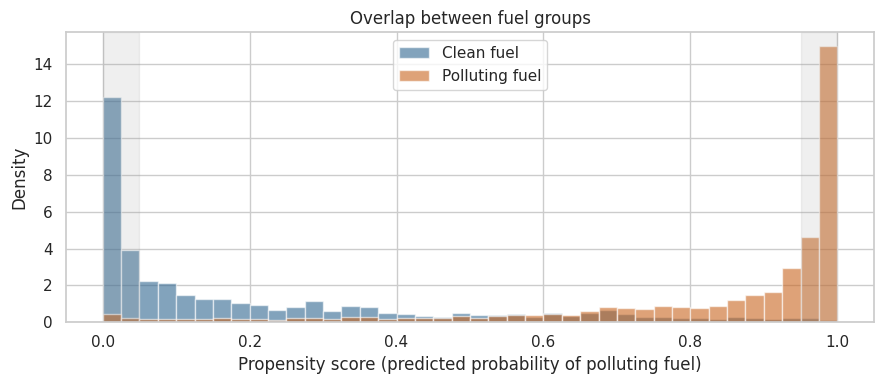

In [ ]:
# ______________________________________________________________________________
# 6.2  OVERLAP CHART
# Why: where the two histograms overlap, there are comparable children in
#      both fuel groups. Where only one colour appears, the comparison rests
#      on extrapolation. Shaded tails mark near-certain fuel types.
# ______________________________________________________________________________


fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 41)
ax.hist(df.loc[T == 0, 'pscore'], bins=bins, alpha=0.6, color='#2F6690', density=True, label='Clean fuel')
ax.hist(df.loc[T == 1, 'pscore'], bins=bins, alpha=0.6, color='#C8641E', density=True, label='Polluting fuel')
ax.axvspan(0, 0.05, color='#999999', alpha=0.15); ax.axvspan(0.95, 1, color='#999999', alpha=0.15)
ax.set_xlabel('Propensity score (predicted probability of polluting fuel)'); ax.set_ylabel('Density')
ax.set_title('Overlap between fuel groups'); ax.legend()
plt.tight_layout(); plt.show()

Largest imbalance |SMD|  before: 0.93   IPW: 0.15   overlap: 0.00
Effective sample size    IPW: 4,662   overlap: 9,708   (of 44,650)
Largest single weight    IPW: 240   overlap: 8.8


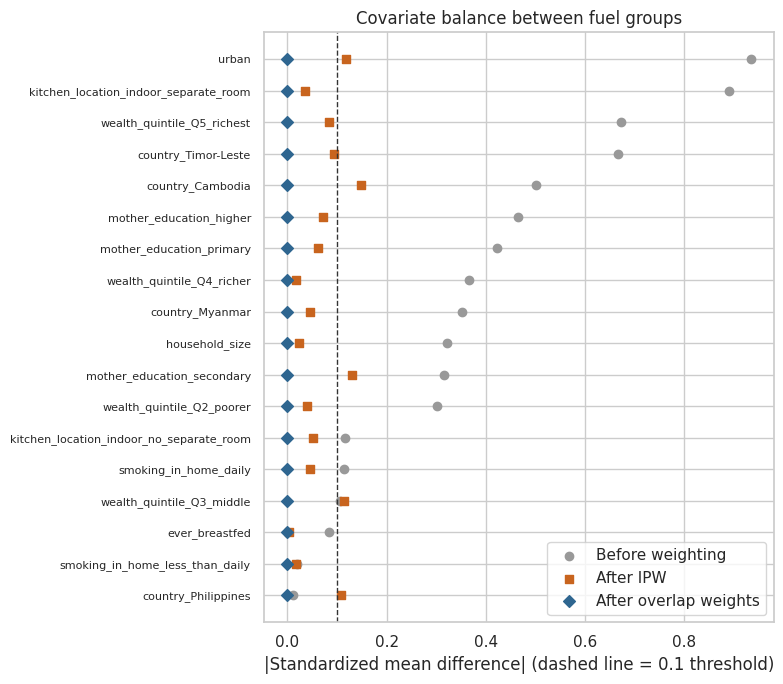

In [ ]:
# ______________________________________________________________________________
# 6.3  WEIGHTS & BALANCE CHECK
# Why: two weighting schemes, each multiplied by the survey weight:
#      (a) IPW (inverse probability weights): the classic approach; estimates
#          the effect for all children, but extreme scores create huge weights.
#      (b) Overlap weights: give most weight to children who could plausibly
#          be in either group; built for poor overlap, and balance exactly.
#      Balance = standardized mean difference (SMD) between fuel groups;
#      under 0.1 is the usual threshold for "well balanced". Overlap weights
#      balance every covariate exactly by construction, so their zeros confirm
#      the method worked; they are not extra evidence on their own.
# ______________________________________________________________________________


ps_trim = df['pscore'].clip(0.01, 0.99)                              # trim to limit extreme IPW weights
df['w_ipw']     = np.where(T == 1, 1 / ps_trim, 1 / (1 - ps_trim)) * weights
df['w_overlap'] = np.where(T == 1, 1 - df['pscore'], df['pscore']) * weights

def smd(col, w):
    # Standardized mean difference between polluting and clean fuel groups
    x = df[col].astype(float).values
    m1, m0 = np.average(x[T == 1], weights=w[T == 1]), np.average(x[T == 0], weights=w[T == 0])
    v1 = np.average((x[T == 1] - m1) ** 2, weights=w[T == 1]); v0 = np.average((x[T == 0] - m0) ** 2, weights=w[T == 0])
    return (m1 - m0) / np.sqrt((v1 + v0) / 2)

balance = pd.DataFrame({
    'before':          [smd(c, weights.values) for c in PS_COVARIATES],
    'after_ipw':       [smd(c, df['w_ipw'].values) for c in PS_COVARIATES],
    'after_overlap':   [smd(c, df['w_overlap'].values) for c in PS_COVARIATES]}, index=PS_COVARIATES)

def ess(w):
    # Effective sample size: how many equally weighted children the weights are worth
    return w.sum() ** 2 / (w ** 2).sum()

print(f"Largest imbalance |SMD|  before: {balance['before'].abs().max():.2f}   "
      f"IPW: {balance['after_ipw'].abs().max():.2f}   overlap: {balance['after_overlap'].abs().max():.2f}")
print(f"Effective sample size    IPW: {ess(df['w_ipw']):,.0f}   overlap: {ess(df['w_overlap']):,.0f}   (of {len(df):,})")
print(f"Largest single weight    IPW: {df['w_ipw'].max():.0f}   overlap: {df['w_overlap'].max():.1f}")

# Love plot: imbalance before and after weighting
bl = balance.reindex(balance['before'].abs().sort_values().index)
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(bl['before'].abs(), range(len(bl)), color='#999999', label='Before weighting')
ax.scatter(bl['after_ipw'].abs(), range(len(bl)), color='#C8641E', marker='s', label='After IPW')
ax.scatter(bl['after_overlap'].abs(), range(len(bl)), color='#2F6690', marker='D', label='After overlap weights')
ax.axvline(0.1, color='#333333', ls='--', lw=1)
ax.set_yticks(range(len(bl))); ax.set_yticklabels([(c[2:] if c.startswith('d_') else c).replace('_label', '') for c in bl.index], fontsize=8)
ax.set_xlabel('|Standardized mean difference| (dashed line = 0.1 threshold)')
ax.set_title('Covariate balance between fuel groups'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [ ]:
# ______________________________________________________________________________
# 6.4  WEIGHTED ARI COMPARISON WITH BOOTSTRAP CONFIDENCE INTERVALS
# Why: with balanced groups, the effect is simply the difference in weighted
#      ARI rates. Confidence intervals come from a cluster bootstrap: resample
#      whole survey clusters 300 times, refit the propensity model each time,
#      and take the middle 95% of results. This accounts for clustering and
#      for uncertainty in the propensity scores themselves.
# ______________________________________________________________________________


Y, SW, Xv_ps = df['ari'].values, weights.values, X_ps.values

def logit_probs(Xm, tm, wm, iters=25):
    # Weighted logistic regression by Newton's method; returns predicted probabilities.
    # Gives the same estimates as statsmodels (checked to 1e-14) but uses far less
    # memory, which matters when the model is refitted 300 times in the bootstrap.
    b = np.zeros(Xm.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(Xm @ b, -30, 30)))
        step = np.linalg.solve((Xm * (wm * p * (1 - p))[:, None]).T @ Xm, Xm.T @ (wm * (tm - p)))
        b += step
        if np.max(np.abs(step)) < 1e-8:
            break
    return 1 / (1 + np.exp(-np.clip(Xm @ b, -30, 30)))

assert np.allclose(logit_probs(Xv_ps, T.astype(float), SW), df['pscore'].values, atol=1e-8)   # matches 6.1

def ps_effects(Xm, Tm, Ym, SWm):
    # Refit propensity model, then return risk difference (pp) and risk ratio for both weightings
    p = logit_probs(Xm, Tm.astype(float), SWm)
    out = {}
    for name, w in {'IPW': np.where(Tm == 1, 1 / np.clip(p, .01, .99), 1 / (1 - np.clip(p, .01, .99))) * SWm,
                    'Overlap weights': np.where(Tm == 1, 1 - p, p) * SWm}.items():
        r1, r0 = np.average(Ym[Tm == 1], weights=w[Tm == 1]), np.average(Ym[Tm == 0], weights=w[Tm == 0])
        out[name] = (r1 * 100, r0 * 100, (r1 - r0) * 100, r1 / r0)
    return out

point = ps_effects(Xv_ps, T, Y, SW)

rng = np.random.default_rng(42)
cluster_rows = pd.Series(np.arange(len(df))).groupby(clusters.values).apply(np.array).values
boot = {'IPW': [], 'Overlap weights': []}
for b in range(300):
    rows = np.concatenate(cluster_rows[rng.integers(0, len(cluster_rows), len(cluster_rows))])
    est = ps_effects(Xv_ps[rows], T[rows], Y[rows], SW[rows])
    for k in boot: boot[k].append(est[k])

ps_results = []
for k in ['Overlap weights', 'IPW']:
    bk = np.array(boot[k])
    ps_results.append({'method': k, 'ARI % polluting': point[k][0], 'ARI % clean': point[k][1],
                       'risk_difference_pp': point[k][2], 'rd_ci_low': np.percentile(bk[:, 2], 2.5), 'rd_ci_high': np.percentile(bk[:, 2], 97.5),
                       'risk_ratio': point[k][3], 'rr_ci_low': np.percentile(bk[:, 3], 2.5), 'rr_ci_high': np.percentile(bk[:, 3], 97.5)})
ps_results = pd.DataFrame(ps_results).set_index('method')
ps_results.round(3)

,ARI % polluting,ARI % clean,risk_difference_pp,rd_ci_low,rd_ci_high,risk_ratio,rr_ci_low,rr_ci_high
method,,,,,,,,
Overlap weights,3.252,3.658,-0.406,-1.138,0.277,0.889,0.725,1.084
IPW,2.898,3.949,-1.051,-2.538,0.116,0.734,0.514,1.034


In [ ]:
# ______________________________________________________________________________
# 6.5  COCHRAN–ARMITAGE TREND TEST ACROSS EXPOSURE LEVELS
# Why: tests for a steady rise in ARI across the four ordered exposure levels
#      (scored 0–3). Run (a) pooled, (b) within each country, and (c) combined
#      across countries (stratified, so country differences cannot create a
#      false trend). These counts are unweighted and unadjusted. (d) then
#      repeats the trend inside the main survey-weighted, fully adjusted model.
# ______________________________________________________________________________


df['exposure_score'] = df['hap_exposure_level'].str[0].astype(int)   # 0 clean ... 3 polluting indoors, no kitchen

def trend_parts(sub):
    # Cochran–Armitage statistic and its variance for one group
    x, yy = sub['exposure_score'].values.astype(float), sub['ari'].values.astype(float)
    n, m = len(x), yy.sum()
    stat = (x * yy).sum() - m * x.mean()
    var = m * (n - m) / (n ** 2 * (n - 1)) * (n * (x ** 2).sum() - x.sum() ** 2)
    return stat, var

def z_p(stat, var):
    z = stat / np.sqrt(var); return z, 2 * norm.sf(abs(z))

rows = [('(a) Pooled, all five countries', *z_p(*trend_parts(df)))]
tot_stat = tot_var = 0
for ct in COUNTRY_ORDER:
    st, va = trend_parts(df[df['country'] == ct]); tot_stat += st; tot_var += va
    rows.append((f'(b) {ct}', *z_p(st, va)))
rows.append(('(c) Stratified by country (combined)', *z_p(tot_stat, tot_var)))
trend = pd.DataFrame(rows, columns=['test', 'z', 'p_value']).set_index('test')
print(trend.round(4), '\n')

NON_KITCHEN = [c for c in FULL if c != EXPOSURE and c not in KITCHEN_D]
m_trend_adj = fit_logit(df, ['exposure_score'] + NON_KITCHEN)
print('(d) Adjusted trend, OR per exposure level:', or_row(m_trend_adj, 'exposure_score'))

                                           z  p_value
test                                                 
(a) Pooled, all five countries        3.7802   0.0002
(b) Cambodia                          2.2943   0.0218
(b) Indonesia                         3.1050   0.0019
(b) Myanmar                           3.5609   0.0004
(b) Philippines                       2.0351   0.0418
(b) Timor-Leste                       1.6968   0.0897
(c) Stratified by country (combined)  5.6187   0.0000 

(d) Adjusted trend, OR per exposure level: OR 1.05 (95% CI 0.97–1.14), p = 0.196


---
# Part 7 · Model Fit
How well does the main model describe the data? Two checks: **discrimination** (can it tell children with ARI from those without?) and **calibration** (do predicted risks match observed risks?).

Weighted AUC: 0.667


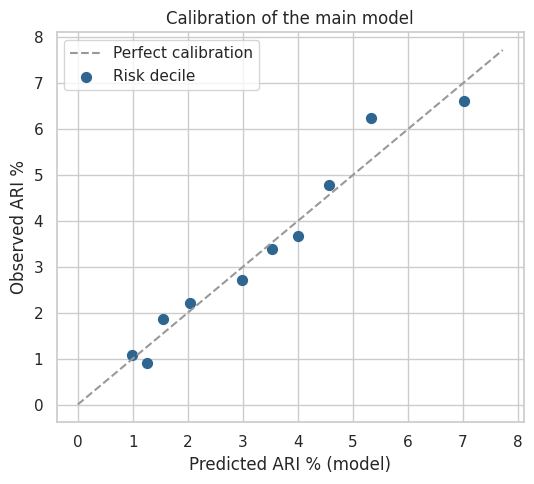

decile,0,1,2,3,4,5,6,7,8,9
predicted,0.98,1.27,1.55,2.05,2.99,3.53,4.01,4.57,5.34,7.02
observed,1.07,0.90,1.85,2.21,2.71,3.38,3.66,4.79,6.25,6.62


In [ ]:
# ______________________________________________________________________________
# 7.1  DISCRIMINATION (AUC) & CALIBRATION
# Why: AUC = 0.5 is a coin flip, 1.0 perfect. A modest AUC is normal when the
#      outcome depends on many things not measured (age, season, infections).
#      Calibration compares predicted vs observed ARI across ten risk groups;
#      points on the diagonal mean the model's risks are accurate on average.
# ______________________________________________________________________________


pred = m_full.predict(sm.add_constant(df[FULL].astype(float)))
auc = roc_auc_score(y, pred, sample_weight=weights)
print(f'Weighted AUC: {auc:.3f}')

cal = pd.DataFrame({'pred': pred, 'obs': y, 'w': weights})
cal['decile'] = pd.qcut(cal['pred'], 10, labels=False, duplicates='drop')
cal_g = cal.groupby('decile').apply(lambda g: pd.Series({
    'predicted': np.average(g['pred'], weights=g['w']) * 100,
    'observed':  np.average(g['obs'],  weights=g['w']) * 100}))

fig, ax = plt.subplots(figsize=(5.5, 5))
lim = max(cal_g.max()) * 1.1
ax.plot([0, lim], [0, lim], ls='--', color='#999999', label='Perfect calibration')
ax.scatter(cal_g['predicted'], cal_g['observed'], color='#2F6690', s=50, label='Risk decile')
ax.set_xlabel('Predicted ARI % (model)'); ax.set_ylabel('Observed ARI %')
ax.set_title('Calibration of the main model'); ax.legend()
plt.tight_layout(); plt.show()
cal_g.round(2).T

---
# Part 8 · Visualizations
Forest plots show each odds ratio as a dot with its 95% confidence interval as a line. The vertical line at **1** means "no difference". **A line that crosses 1 is not statistically distinguishable from no difference.**

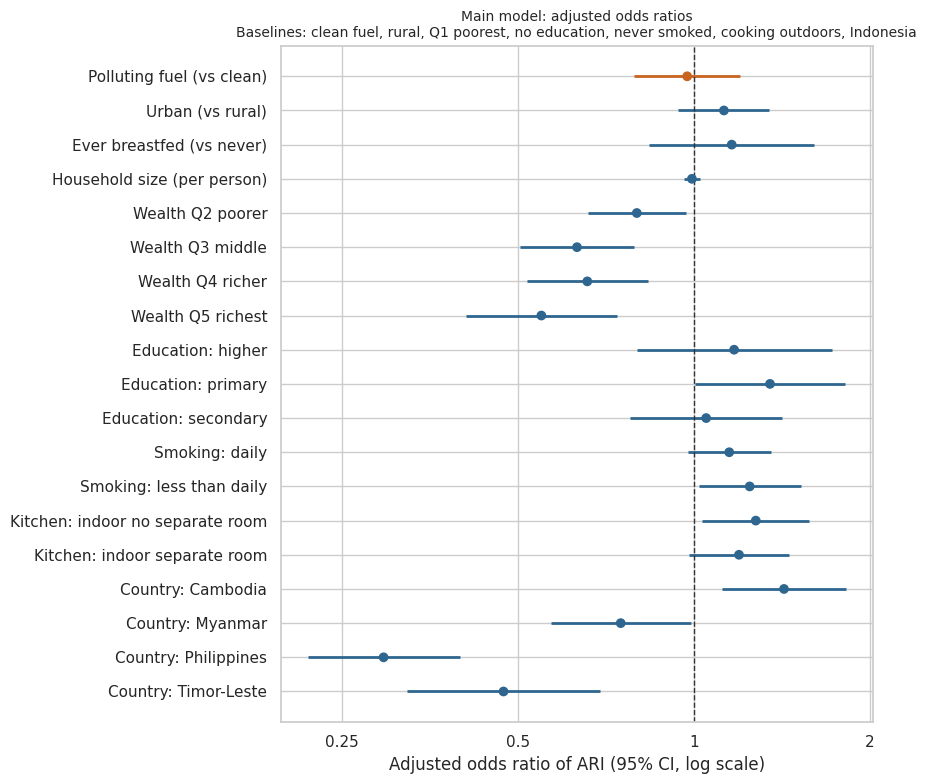

In [ ]:
# ______________________________________________________________________________
# 8.1  FOREST PLOT: MAIN MODEL
# Why: shows every predictor's adjusted odds ratio at once, so the size and
#      certainty of the fuel result can be compared with the covariates.
#      Log scale: an OR of 2 and of 0.5 sit the same distance from 1.
# ______________________________________________________________________________


labels = {'solid_fuel': 'Polluting fuel (vs clean)', 'urban': 'Urban (vs rural)',
          'ever_breastfed': 'Ever breastfed (vs never)', 'household_size': 'Household size (per person)'}
plot = main.copy()
plot.index = [labels.get(i, i.replace('d_wealth_quintile_label_', 'Wealth ').replace('d_mother_education_', 'Education: ')
                             .replace('d_smoking_in_home_', 'Smoking: ').replace('d_kitchen_location_', 'Kitchen: ')
                             .replace('d_country_', 'Country: ').replace('_', ' ')) for i in plot.index]
plot = plot.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 8))
colors = ['#C8641E' if 'Polluting fuel' in i else '#2F6690' for i in plot.index]
ax.errorbar(plot['odds_ratio'], range(len(plot)),
            xerr=[plot['odds_ratio'] - plot['ci_low'], plot['ci_high'] - plot['odds_ratio']],
            fmt='none', ecolor=colors, elinewidth=2)
ax.scatter(plot['odds_ratio'], range(len(plot)), color=colors, zorder=3)
ax.axvline(1, color='#333333', ls='--', lw=1)
ax.set_xscale('log'); ax.set_xticks([0.25, 0.5, 1, 2]); ax.set_xticklabels(['0.25', '0.5', '1', '2'])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot.index)
ax.set_xlabel('Adjusted odds ratio of ARI (95% CI, log scale)')
ax.set_title('Main model: adjusted odds ratios\nBaselines: clean fuel, rural, Q1 poorest, no education, never smoked, cooking outdoors, Indonesia', fontsize=10)
plt.tight_layout(); plt.show()

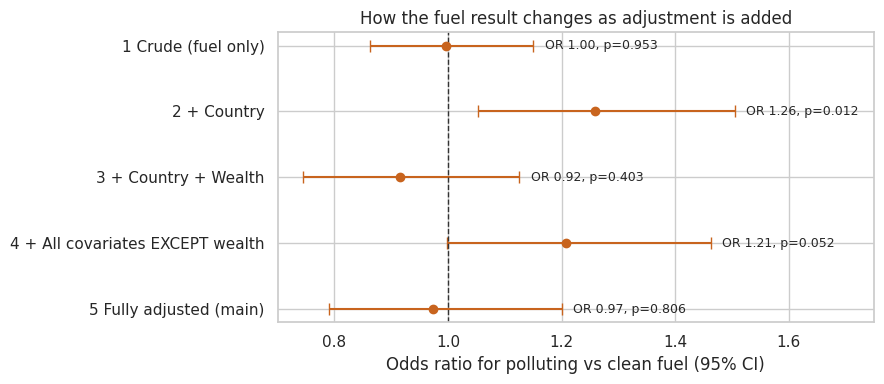

In [ ]:
# ______________________________________________________________________________
# 8.2  THE ADJUSTMENT PATH
# Why: the single most informative chart: it shows the fuel OR rising when
#      countries are compared fairly, then falling back to ~1 once wealth is
#      added. The result depends on how wealth is treated.
# ______________________________________________________________________________


fig, ax = plt.subplots(figsize=(9, 4))
ypos = range(len(path))[::-1]
ax.errorbar(path['odds_ratio'], ypos, xerr=[path['odds_ratio'] - path['ci_low'], path['ci_high'] - path['odds_ratio']],
            fmt='o', color='#C8641E', ecolor='#C8641E', capsize=4)
for yy, (_, r) in zip(ypos, path.iterrows()):
    ax.text(r['ci_high'] + 0.02, yy, f"OR {r['odds_ratio']:.2f}, p={r['p_value']:.3f}", va='center', fontsize=9)
ax.axvline(1, color='#333333', ls='--', lw=1)
ax.set_yticks(list(ypos)); ax.set_yticklabels(path.index)
ax.set_xlim(0.7, 1.75)
ax.set_xlabel('Odds ratio for polluting vs clean fuel (95% CI)')
ax.set_title('How the fuel result changes as adjustment is added')
plt.tight_layout(); plt.show()

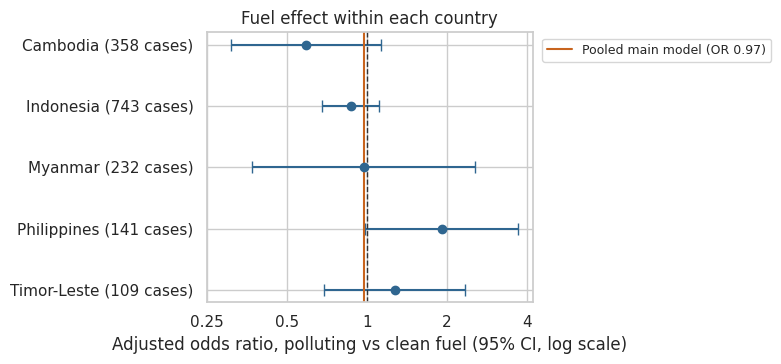

In [ ]:
# ______________________________________________________________________________
# 8.3  FOREST PLOT: FUEL EFFECT IN EACH COUNTRY
# Why: shows whether the null pooled result hides opposite effects in
#      different countries. Wide lines = few cases = little certainty.
# ______________________________________________________________________________


bc = by_country.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(bc['odds_ratio'], range(len(bc)), xerr=[bc['odds_ratio'] - bc['ci_low'], bc['ci_high'] - bc['odds_ratio']],
            fmt='o', color='#2F6690', capsize=4)
ax.axvline(1, color='#333333', ls='--', lw=1)
pooled = main.loc[EXPOSURE]
ax.axvline(pooled.odds_ratio, color='#C8641E', lw=1.5, label=f'Pooled main model (OR {pooled.odds_ratio:.2f})')
ax.set_xscale('log'); ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(['0.25', '0.5', '1', '2', '4'])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(bc))); ax.set_yticklabels([f'{i} ({int(r.ari_cases)} cases)' for i, r in bc.iterrows()])
ax.set_xlabel('Adjusted odds ratio, polluting vs clean fuel (95% CI, log scale)')
ax.set_title('Fuel effect within each country'); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout(); plt.show()

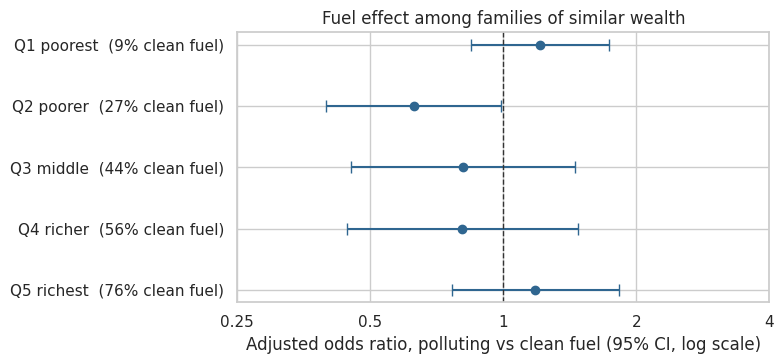

In [ ]:
# ______________________________________________________________________________
# 8.4  FUEL EFFECT BY WEALTH LEVEL
# Why: the visual answer to Part 5: if fuel mattered independently of wealth,
#      the dots would sit consistently to the right of 1. Each label shows
#      the % of children in that quintile whose homes use clean fuel.
# ______________________________________________________________________________


bw = by_wealth.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(bw['odds_ratio'], range(len(bw)), xerr=[bw['odds_ratio'] - bw['ci_low'], bw['ci_high'] - bw['odds_ratio']],
            fmt='o', color='#2F6690', capsize=4)
ax.axvline(1, color='#333333', ls='--', lw=1)
ax.set_xscale('log'); ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(['0.25', '0.5', '1', '2', '4'])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(bw)))
ax.set_yticklabels([f'{i}  ({r.pct_clean_fuel:.0f}% clean fuel)' for i, r in bw.iterrows()])
ax.set_xlabel('Adjusted odds ratio, polluting vs clean fuel (95% CI, log scale)')
ax.set_title('Fuel effect among families of similar wealth')
plt.tight_layout(); plt.show()

---
# Part 9 · Interpretation

> **Note:** this is the preliminary interpretation, written before stress testing. The final version is in **Part 10**.

## Step 1 · Four key numbers (copied from `logistic_regression_output.txt`)

| Number | Value |
|---|---|
| **Test statistic** | Adjusted odds ratio for polluting vs clean fuel = **0.97** (95% CI 0.79–1.20) |
| **P-value** | **0.81** |
| **Effect size** | Odds ratio **0.97** (for logistic regression, the odds ratio is the effect size) |
| **Sample size** | **44,650 children**, 1,583 with ARI, from 4,710 survey clusters (all rows; no missing data) |

## Steps 2–4 · Three-sentence interpretation

**1. Pattern.** Children under five in Cambodia, Indonesia, Myanmar, the Philippines and Timor-Leste showed no detectable difference in respiratory infection symptoms between homes that cook with polluting fuel and homes that cook with clean fuel, once household wealth and the other factors were taken into account.

**2. Strength.** The adjusted odds ratio was 0.97 (95% CI 0.79–1.20, p = 0.81) across 44,650 children and 1,583 ARI cases, so the association is undetectable rather than merely uncertain: a sample this size rules out polluting fuel raising the odds of ARI by more than about 20% in this model.

**3. Surprise / limit.** The surprise is that the answer hinges on wealth: comparing children within the same country, polluting fuel was linked to 26% higher odds of ARI (OR 1.26, p = 0.012), but adding the DHS wealth index erased it (OR 0.92 with country and wealth alone), and because that index is built from household characteristics that can include cooking fuel itself, I cannot yet tell whether wealth is genuinely explaining the fuel effect or absorbing part of it.

## Supporting results (secondary, not the headline)

| Analysis | Result | What it means |
|---|---|---|
| Adjustment path (3.5) | Crude 1.00 → country 1.26 (p = 0.012) → + wealth 0.92 → all except wealth 1.21 (p = 0.052) → full 0.97 | **Wealth alone** moves the result; the other covariates barely do |
| Cooking indoors with no separate kitchen (4.1a) | OR 1.28 (1.03–1.58), p = 0.023 vs cooking outdoors | Cooking location matters even after accounting for fuel type; possibly enclosed smoke, possibly crowded or poorer housing |
| Exposure gradient (4.1b) | Polluting fuel indoors with no separate kitchen OR 1.14 (0.86–1.49), p = 0.36 vs clean fuel | The "smokiest setting" pattern from Notebook 1 points the right way but is not distinguishable from chance after adjustment |
| Kerosene separated (4.2) | Kerosene 1.00, biomass 0.97 vs clean | Counting kerosene as polluting did not change the result |
| Fuel × country (4.3) | Wald p = 0.23 | No evidence the fuel effect differs by country, so one pooled estimate is reasonable (with limited power to detect differences) |
| Each country (4.4) | ORs 0.59–1.91; all CIs cross 1; Philippines 1.91, p = 0.055 | Too few cases per country for certainty; the Philippines is the one borderline signal |
| Unweighted (4.5a) | OR 1.00 (0.86–1.17) | Weighting does not drive the result |
| Mantel-Haenszel, country only (4.5b) | OR 1.29 (1.14–1.45) | Independently reproduces the country-adjusted 1.26: the within-country signal is real **before** wealth is considered |
| Wealth | Richest fifth OR 0.55 (0.41–0.74) vs poorest | The strongest predictor in the model: poverty is tightly linked to ARI |
| Model fit (7.1) | AUC 0.67; calibration close to the diagonal | Modest discrimination, as expected when age, season and infections are unmeasured; predicted risks are accurate on average |

## What the follow-up analyses add (Part 5)

| Analysis | Result | What it means |
|---|---|---|
| Fuel within each wealth quintile (5.1) | ORs 0.63–1.21; no consistent direction; only Q2 reaches p < 0.05, and in the **opposite** direction (0.63) | Among families of similar wealth, polluting fuel does not consistently predict more ARI, even in Q3–Q5 where both fuel types are common |
| Fuel × wealth (5.2) | Joint p = 0.16; trend p = 0.08 | No clear evidence that fuel matters more for poorer or richer children |
| Age proxy: older sibling (5.3) | OR 0.63 (0.52–0.76), p < 0.001 | Younger children (the most recent birth) have much more ARI, confirming age matters. Adding it does **not** change the fuel result (0.98) |
| Mother's age (tested during development) | OR 1.00 per year, p = 0.54 | No effect, so not kept in the notebook |
| Education + urban instead of wealth (5.4) | Fuel OR 1.22 (1.01–1.48), p = 0.038 with the age proxy | Without the wealth index, a modest fuel link remains |

**Overall reading.** The fuel–ARI link is **small at most** and depends on how socioeconomic status is measured: about 20% higher odds when status is measured by education and residence, none when it is measured by the wealth index, and no consistent effect among families of similar wealth. The within-quintile results lean toward **wealth being a genuine confounder** rather than the index simply absorbing a fuel effect, but they are not decisive, because the quintiles themselves are built partly from fuel. The defensible conclusion is that **in these five surveys, household wealth predicts child ARI far more strongly than cooking fuel does.**

## What the alternative approaches add (Part 6)

| Analysis | Result | What it means |
|---|---|---|
| Overlap between fuel groups (6.1–6.2) | 47% of children have a near-certain fuel type (score < 0.05 or > 0.95) | Many children have no comparable counterpart in the other fuel group. The regression handles this by extrapolating; propensity weighting makes it visible |
| **Overlap weights (6.4, main propensity result)** | ARI 3.25% polluting vs 3.66% clean: risk difference **−0.4 percentage points** (95% CI −1.1 to +0.3); risk ratio 0.89 (0.73–1.08) | Among children who could plausibly live in either kind of home, polluting fuel shows no higher ARI risk. The data rule out more than about an 8% increase in risk in this group |
| IPW (6.4, comparison) | Risk difference −1.1 pp (−2.5 to +0.1); risk ratio 0.73 (0.51–1.03) | Same conclusion, but less trustworthy: a few children get weights up to 240, the effective sample shrinks to about 4,700, and balance is not fully achieved |
| Trend test, within countries (6.5c) | z = 5.62, p < 0.0001; significant in 4 of 5 countries | Unadjusted, ARI rises steadily with exposure level inside each country: the dose–response pattern from Notebook 1 is real in the raw data |
| Trend, fully adjusted (6.5d) | OR 1.05 per exposure level (0.97–1.14), p = 0.20 | Once wealth and the other factors are accounted for, the trend is no longer distinguishable from chance |

**What the two methods together show.** A completely different method reaches the same answer as the regression: once children are compared with others in similar circumstances, polluting fuel is not associated with more ARI. The trend test shows the same story for the dose–response question: a clear gradient in the raw data that disappears after adjustment. Agreement across logistic regression, propensity weighting, within-wealth comparisons and the trend test makes the finding much harder to dismiss as an artifact of one modelling choice. The one thing none of them can settle is whether the wealth index itself absorbs part of the fuel effect (Part 10, limitation 1).

---
# Part 10 · Limitations & Final Conclusion

This is the **final notebook** of the analysis; no further notebooks follow. This part records what the result cannot tell you, the stress-tested interpretation that replaces the preliminary one in Part 9, and the further work that would settle the open questions for anyone who extends this analysis.

**What this result cannot tell you**
1. **Wealth: confounder or over-adjustment?** This is the central open question. Part 5 leans toward confounding (no consistent fuel effect within wealth quintiles), but cannot settle it. If the DHS wealth index in these five surveys includes cooking fuel, adjusting for it partly adjusts for the exposure itself and pushes the fuel OR toward 1. With family circumstances measured by mother's education and urban residence instead (Part 5.4), a modest link appears (OR 1.22, p = 0.038).
2. **No child age.** Age is one of the strongest ARI predictors and is not in the extract. Birth position (older sibling vs most recent birth) is only a rough proxy; it is strongly linked to ARI but did not change the fuel result (Part 5.3). Residual confounding by exact age remains.
3. **Cross-sectional, self-reported data.** Association only, not causation. Mothers' 2-week recall of symptoms and a single "main cooking fuel" answer both misclassify, which usually pulls results toward no effect.
4. **ARI definition across DHS rounds.** Cambodia 2014 is DHS-6; the others are DHS-7. Not verified.
5. **Multiple comparisons.** About 35 fuel–ARI comparisons were run across Parts 3–6. The borderline positive results (kitchen with no separate room, p = 0.023; wealth-free adjustment, p = 0.038; the Philippines, p = 0.055) would probably not survive a false discovery rate correction, so treat them as leads, not findings.
6. **Survey design approximation.** Weights and cluster-robust standard errors are used, but not strata. This usually makes intervals slightly wider (more conservative), not narrower.
7. **Limited overlap between fuel groups.** About half the children have a near-certain fuel type given their circumstances (Part 6). The overlap-weighted result describes children who could plausibly be in either group; it says little about the poorest rural households, where nearly everyone outside Indonesia cooks with polluting fuel.
8. **The trend test is unweighted.** The Cochran–Armitage test uses raw counts; the adjusted trend (6.5d) is the survey-weighted check.

## Final interpretation (after stress testing)

**1. Pattern.** Among 44,650 children under five in Cambodia, Indonesia, Myanmar, the Philippines and Timor-Leste, those in homes cooking with polluting fuel had higher odds of respiratory infection symptoms than children in clean-fuel homes in the same country (OR 1.26), but that difference was no longer detectable once household wealth and other family circumstances were taken into account.

**2. Strength.** After adjustment the association was not distinguishable from chance (OR 0.97, 95% CI 0.79–1.20, p = 0.81, 1,583 ARI cases), and three other approaches agreed (within-wealth comparison, propensity-score weighting and a trend test). Because the interval still allows up to about a 20% increase in odds, and mother-reported symptoms and a single "main fuel" answer tend to pull estimates toward no difference, the result is consistent with no effect or a modest one; it does not rule a modest effect out.

**3. Surprise / limit.** Household wealth, not cooking fuel, was the clearest predictor (richest fifth vs poorest OR 0.55, p = 0.0001). But the DHS wealth index is partly built from cooking fuel itself, and with a fuel-free measure of family circumstances polluting fuel was linked to about 22% higher odds (p = 0.038), a lead rather than a finding given about 35 comparisons, so it remains open whether wealth is a true confounder or partly absorbs a real fuel effect.

**What changed from Part 9.** "Rules out more than about 20%" became "does not rule a modest effect out", because measurement error pulls toward no difference and the estimate moves with how wealth is measured. The wealth overlap moved from a closing caveat to the main limit, now backed by the Part 5.4 result.

## Further work (outside the scope of this project)
These would settle the open questions but need new data or new analysis beyond this notebook:
- **Rebuild the wealth index without cooking fuel** (re-pull the household asset variables from IPUMS-DHS and recreate the index), then refit. This is the direct test of limitation 1.
- **Re-pull with child age in months and interview month** (season) and add them to the main model.
- **Verify the ARI definition** for each DHS round and refit with the alternative definition.
- **Apply a false discovery rate correction** across the fuel comparisons.
